# 02 - Cleaning, (input, target) construction and leakage-safe split

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import pandas as pd, numpy as np, matplotlib.pyplot as plt, json
pd.set_option("display.max_colwidth", 160); pd.set_option("display.width", 200)
%matplotlib inline
from src import config as C
from src.data_loader import load_datatourisme
from src.data_cleaning import clean_datatourisme, clean_text
from src.pairs import build_pairs, group_split, split_report

## Text cleaning, one function applied to titles and descriptions

In [2]:
samples = ["<p>Concert &amp; dégustation !!!</p> Infos : www.mairie.fr / 06 12 34 56 78",
           "Les Débhordeurs de la cie BROUN\\u00cfAK.Venez nombreux 🎉🎉",
           "Réservation : www\\.domaine\\-citadelle\\.com. Dès 12 ans"]
for s in samples: print(repr(s), "\n ->", clean_text(s), "\n")

'<p>Concert &amp; dégustation !!!</p> Infos : www.mairie.fr / 06 12 34 56 78' 
 -> Concert & dégustation ! Infos 

'Les Débhordeurs de la cie BROUN\\u00cfAK.Venez nombreux 🎉🎉' 
 -> Les Débhordeurs de la cie BROUNÏAK. Venez nombreux 

'Réservation : www\\.domaine\\-citadelle\\.com. Dès 12 ans' 
 -> Réservation : Dès 12 ans 



Removed: HTML tags/entities, URLs, e-mails and phone numbers (no information for generation and
personal contact data), emojis and control characters, literal `\uXXXX` escapes (an encoding problem found
in the EDA), markdown escapes, repeated punctuation and line breaks. Kept: accents, case, punctuation and
sentence structure.

In [3]:
clean, rep = clean_datatourisme(load_datatourisme())
pd.DataFrame(rep['steps'])

,step,removed,remaining,reason
0,duplicate_event_id,0,73747,same DATAtourisme URI twice
1,missing_description,34635,39112,no target text: cannot be a training pair (never fabricated)
2,missing_title,0,39112,title is the essential input field
3,non_french,0,39112,single-language (French) model
4,empty_after_cleaning,3,39109,description contained only URL / phone / e-mail / tags
5,description_equals_title,443,38666,target identical to input: nothing to generate
6,duplicate_pair,1271,37395,"same (title, description) published twice (recurring dates)"
7,duplicate_description,2150,35245,identical description shared by different events (boilerplate); one kept to avoid memorisation and leakage


In [4]:
print('initial', rep['initial_rows'], '-> final', rep['final_rows'])
print('empty columns dropped:', rep['empty_columns_dropped'])
print('rows with corrupted / generic type kept (input = "non précisé"):', rep['corrupted_type_rows_kept'])

initial 73747 -> final 35245
empty columns dropped: ['theme', 'startdate', 'enddate', 'street', 'postalcode', 'city', 'insee', 'latitude', 'longitude', 'email', 'web', 'tel', 'lastupdate']
rows with corrupted / generic type kept (input = "non précisé"): 6642


## Pairs
* **input_text** = `type : <labels> | titre : <title>`: the structured fields that really exist.
* **target_text** = the event's own description (same record, so no join can mismatch them).
* Targets shorter than 8 tokens are dropped; longer than 60 tokens are cut at the **last sentence
  end** inside the window (never mid-sentence).

In [5]:
cfg = C.DataConfig()
pairs, prep = build_pairs(clean, cfg)
prep

{'rows_in': 35245,
 'steps': [{'step': 'too_short_target',
   'removed': 2617,
   'reason': '< 8 tokens'},
  {'step': 'no_sentence_boundary_within_max_len',
   'removed': 132,
   'reason': "> 60 tokens and no '.!?' to cut at"},
  {'step': 'too_short_after_truncation',
   'removed': 10,
   'reason': '< 8 tokens after cut'}],
 'validation': {'empty_input': 0,
  'empty_target': 0,
  'duplicate_pairs': 36,
  'duplicate_ids': 0,
  'target_from_other_event': 0},
 'rows_out': 32450,
 'truncated_targets': 3355}

In [6]:
pairs[['input_text','target_text']].sample(10, random_state=3)

,input_text,target_text
3371,"type : conférence , événement culturel , événement sportif | titre : IA TROP ENVAHISSANTE ?","L'intelligence artificielle s'est invitée sur vos appareils et vous avez envie de dire stop ? Sarah, notre conseillère numérique vous propose un atelier pou..."
13683,type : non précisé | titre : Mai à vélo - Un mois pour adopter un vélo... pour la vie,5 ans déjà que Mai à Vélo fait vibrer la France... et Loos-en-Gohelle avec elle !
4452,"type : musique , concert , événement culturel | titre : Mardis de la musique de chambre #3 : Les musiques du temps des rois","Un voyage au temps des rois : violon baroque, basson et sonates éclatantes de Zelenka à Vivaldi, pour redécouvrir la musique ancienne en toute simplicité."
30909,"type : événement social , événement religieux | titre : La Pastorale d'Yvan Audouard","La Pastorale d'Yvan Audouard. Mise en scène Juliette Subira, ""la Pastorale"" se conçoit avec des comédiens amateurs saint-rémois, petits et grands, qui prenn..."
8822,type : événement sportif | titre : Mardi jeux,La ludothèque s'installe à Pont-de-Barret 1 mardi par mois. Jeux et jouets pour tous les âges.
27735,"type : musique , concert , événement culturel | titre : Concert caritatif de l'Harmonie de Bischoffsheim","Un concert, une belle cause, des émotions à partager ! L'Harmonie de Bischoffsheim vous propose un programme mêlant musiques de cinéma et airs de Noël. Les ..."
17795,"type : projection , événement culturel , événement sportif | titre : Cinéma : Notre salut","Septembre 1940, le régime de Pétain se met en place. Henri Marre, 49 ans, débarque à Vichy sans le sou, sans contact, loin de sa femme et ses enfants. Il vo..."
4990,"type : événement culturel | titre : ""Journal d'un fou"" de Nicolaï Gogol","""Journal d'un fou "" est un spectacle ""seul en scène"" proposé par le Théâtre Atelier Bûle. C'est l'histoire de Poprichtchine, un petit fonctionnaire méprisé ..."
2924,"type : festival , musique , concert , événement culturel | titre : Jammin' Juan","L'événement Jammin'Juan a pour but d'offrir une scène de showcase aux talents émergents du jazz, de leur permettre de se produire devant des décideurs, les ..."
13329,type : non précisé | titre : Printemps des cimetières,Le cimetière militaire d'Etaples : les femmes dans le conflit


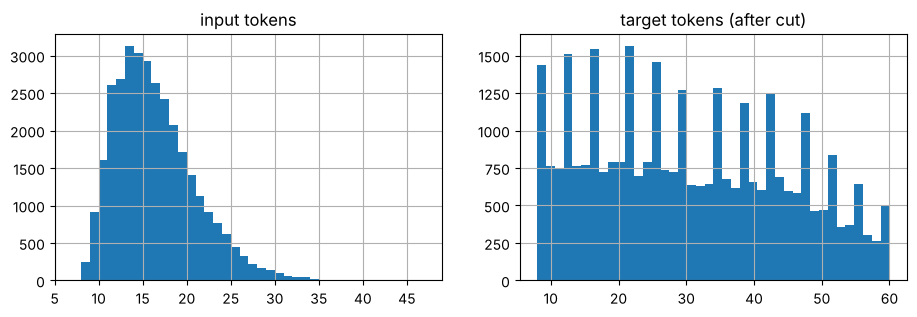

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
pairs.source_tokens.hist(bins=40, ax=ax[0]); ax[0].set_title('input tokens')
pairs.target_tokens.hist(bins=40, ax=ax[1]); ax[1].set_title('target tokens (after cut)')
plt.show()

## Group split 80 / 10 / 10
Records sharing a **title** (a recurring show) or the **same first 12 description tokens**
(templates, near-duplicates) are linked; each connected group goes entirely to one split, so the test
set contains no recycled description.

In [8]:
splits = group_split(pairs, cfg)
split_report(splits)

{'train': {'rows': 25960, 'pct': 80.0},
 'val': {'rows': 3245,
  'pct': 10.0,
  'title_overlap_with_train': 0,
  'description_overlap_with_train': 0},
 'test': {'rows': 3245,
  'pct': 10.0,
  'title_overlap_with_train': 0,
  'description_overlap_with_train': 0}}